# Heyert Notebook
# Project 2: Text Preprocessing


- Author: [Alex Heyert](https://github.com/ajaneh/)
- Repository: [nlp-02-text-preprocessing](https://github.com/ajaneh/nlp-02-text-preprocessing-custom/)
- Purpose: TODO
- Date: 2026-11

## Section 1. Setup and Imports

Imports and configuration appear once, at the top.

WHY:
- Keeps notebooks readable and reproducible
- Mirrors professional scripts
- Makes requirements clear


In [60]:
# Section 1 Python cell.

# Imports at the top of the file
# REQ: External packages must be defined in pyproject.toml
# REQ: External packages must be installed in the environment using `uv sync` command
# REQ: External packages used in this notebook must be imported here

from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


## Section 2. Read the Text Data


In [61]:
# Section 2 Python cell

# In notebooks, start with the current working directory
# where the notebook is located.
NOTEBOOKS_PATH: Path = Path.cwd()
ROOT_PATH: Path = NOTEBOOKS_PATH.parent

DATA_PATH: Path = ROOT_PATH / "data"
NOTEBOOKS_PATH: Path = ROOT_PATH / "notebooks"
SCRIPTS_PATH: Path = ROOT_PATH / "scripts"

# Choose a text file to analyze.
# Each line is treated as one text record.
input_path: Path = DATA_PATH / "clothing_reviews.csv"

# Read the desired columns in from the CSV file.
reviews: pl.DataFrame = (pl.read_csv(input_path)).select("Rating", "Review Text")
print(reviews.null_count())
reviews = reviews.drop_nulls()
text_list: list[str] = reviews["Review Text"].to_list()

print("Data loaded successfully.")
print(f"Loaded {len(text_list):,} text records.")

# Combine all text rows into one large string for simple preprocessing.
raw_text: str = " ".join(text_list)

print(f"Raw text length: {len(raw_text):,} characters")
print("First 500 characters of raw text:")
print(raw_text[:500])

shape: (1, 2)
┌────────┬─────────────┐
│ Rating ┆ Review Text │
│ ---    ┆ ---         │
│ u64    ┆ u64         │
╞════════╪═════════════╡
│ 0      ┆ 845         │
└────────┴─────────────┘
Data loaded successfully.
Loaded 22,641 text records.
Raw text length: 7,011,643 characters
First 500 characters of raw text:
Absolutely wonderful - silky and sexy and comfortable Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite. I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found thi


## Section 3. Inspect the Raw Text


In [62]:
# Section 3 Python cell

# Review the text records before preprocessing.
# This helps confirm the data loaded correctly and gives a
# sense of the structure of the text.

print("First 5 text records:")
for line in text_list[:5]:
    print("-", line)

print(f"\nLoaded {len(text_list):,} text records.")
print(f"Raw text length: {len(raw_text):,} characters")

print("\nFirst 500 characters of combined text:")
print(raw_text[:500])

First 5 text records:
- Absolutely wonderful - silky and sexy and comfortable
- Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite.
- I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c
- I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great

## Section 4. Tokenize the Raw Text


In [63]:
# Section 4 Python cell

# Split the raw text into rough word-like pieces using whitespace.
raw_tokens: list[str] = raw_text.split()
count_of_raw_tokens: int = len(raw_tokens)

print("First 20 raw tokens:")
print(raw_tokens[:20])
print(f"Total raw tokens: {count_of_raw_tokens:,}")

First 20 raw tokens:
['Absolutely', 'wonderful', '-', 'silky', 'and', 'sexy', 'and', 'comfortable', 'Love', 'this', 'dress!', "it's", 'sooo', 'pretty.', 'i', 'happened', 'to', 'find', 'it', 'in']
Total raw tokens: 1,362,913


## Section 5. Normalize the Text


In [64]:
# Section 5 Python cell

# Convert all text to lowercase so words like "Data" and "data"
# are treated as the same token.
lower_text: str = raw_text.lower()

print("First 500 characters of lowercase text:")
print(lower_text[:500])

First 500 characters of lowercase text:
absolutely wonderful - silky and sexy and comfortable love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite. i had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found thi


## Section 6. Remove Punctuation and Tokenize Again


In [65]:
# Section 6 Python cell

""" counts before removing contractions were:
│ raw tokens                ┆ 1362913 │
│ after punctuation removal ┆ 1398169 │
│ after stop word removal   ┆ 784494 

after change:
 │ raw tokens   ┆ 1362913 │
│ after punctuation removal ┆ 1373258 │
│ after stop word removal   ┆ 786415   
So it did make a difference. But there are still extra words"""
# 1. NEW STEP: Strip apostrophes inside contractions first (e.g., "don't" -> "dont")
# This targets apostrophes only when sandwiched between letters, preserving words.
no_contraction_text: str = re.sub(r"(?<=[a-z])'(?=[a-z])", "", lower_text)

# Replace any character that is not a letter, number, or whitespace
# with a space. This removes punctuation and many special characters.
no_punct_text: str = re.sub(r"[^a-z0-9\s]", " ", no_contraction_text)


# Tokenize again after punctuation removal.
tokens_no_punct: list[str] = no_punct_text.split()
count_of_tokens_no_punct: int = len(tokens_no_punct)

print("First 20 tokens after lowercasing and punctuation removal:")
print(tokens_no_punct[:20])
print(f"Total tokens after punctuation removal: {count_of_tokens_no_punct:,}")

First 20 tokens after lowercasing and punctuation removal:
['absolutely', 'wonderful', 'silky', 'and', 'sexy', 'and', 'comfortable', 'love', 'this', 'dress', 'its', 'sooo', 'pretty', 'i', 'happened', 'to', 'find', 'it', 'in', 'a']
Total tokens after punctuation removal: 1,373,258


## Section 7. Remove Stop Words


This is a Markdown cell.

In [66]:
# Section 7 Python cell

# Stop words are very common words that often add little meaning
# for simple frequency analysis.
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

# Keep only tokens that:
# - are longer than 2 characters
# - are not in the stop word list
clean_tokens: list[str] = [
    token for token in tokens_no_punct if len(token) > 2 and token not in STOP_WORDS
]

count_of_clean_tokens: int = len(clean_tokens)

print("First 20 cleaned tokens:")
print(clean_tokens[:20])
print(f"Total cleaned tokens: {count_of_clean_tokens:,}")

First 20 cleaned tokens:
['absolutely', 'wonderful', 'silky', 'sexy', 'comfortable', 'love', 'this', 'dress', 'sooo', 'pretty', 'happened', 'find', 'store', 'glad', 'did', 'never', 'would', 'ordered', 'online', 'petite']
Total cleaned tokens: 786,415


## Section 8. Build a Before/After Summary Table


In [67]:
# Section 8 Python cell

summary_df: pl.DataFrame = pl.DataFrame(
    {
        "stage": [
            "raw tokens",
            "after punctuation removal",
            "after stop word removal",
        ],
        "count": [
            count_of_raw_tokens,
            count_of_tokens_no_punct,
            count_of_clean_tokens,
        ],
    }
)

print("Preprocessing summary:")
decimal_count = len(re.findall(r"\d\.\d", lower_text))
print(f"Found {decimal_count} numbered decimals in the text.")
print(f"Which would mean {decimal_count * 2} more tokens")
print(f"The overall difference is {count_of_tokens_no_punct - count_of_raw_tokens}")
print(summary_df)

Preprocessing summary:
Found 242 numbered decimals in the text.
Which would mean 484 more tokens
The overall difference is 10345
shape: (3, 2)
┌───────────────────────────┬─────────┐
│ stage                     ┆ count   │
│ ---                       ┆ ---     │
│ str                       ┆ i64     │
╞═══════════════════════════╪═════════╡
│ raw tokens                ┆ 1362913 │
│ after punctuation removal ┆ 1373258 │
│ after stop word removal   ┆ 786415  │
└───────────────────────────┴─────────┘


## Section 9. Build a Frequency Table with Polars


In [68]:
# Section 9 Python cell

# Create a Polars DataFrame with one row per cleaned token.
token_df: pl.DataFrame = pl.DataFrame({"token": clean_tokens})

# Group by token, count occurrences, and sort from most common to least common.
freq_df: pl.DataFrame = token_df.group_by("token").len().sort("len", descending=True)

print("Top 20 most frequent cleaned tokens:")
print(freq_df.head(20))

Top 20 most frequent cleaned tokens:
shape: (20, 2)
┌────────┬───────┐
│ token  ┆ len   │
│ ---    ┆ ---   │
│ str    ┆ u64   │
╞════════╪═══════╡
│ this   ┆ 25762 │
│ dress  ┆ 10561 │
│ not    ┆ 9799  │
│ love   ┆ 8951  │
│ size   ┆ 8772  │
│ …      ┆ …     │
│ they   ┆ 4990  │
│ fabric ┆ 4793  │
│ small  ┆ 4728  │
│ color  ┆ 4605  │
│ look   ┆ 4039  │
└────────┴───────┘


## Section 10. Build a "Most Frequent Cleaned Tokens" Bar Chart


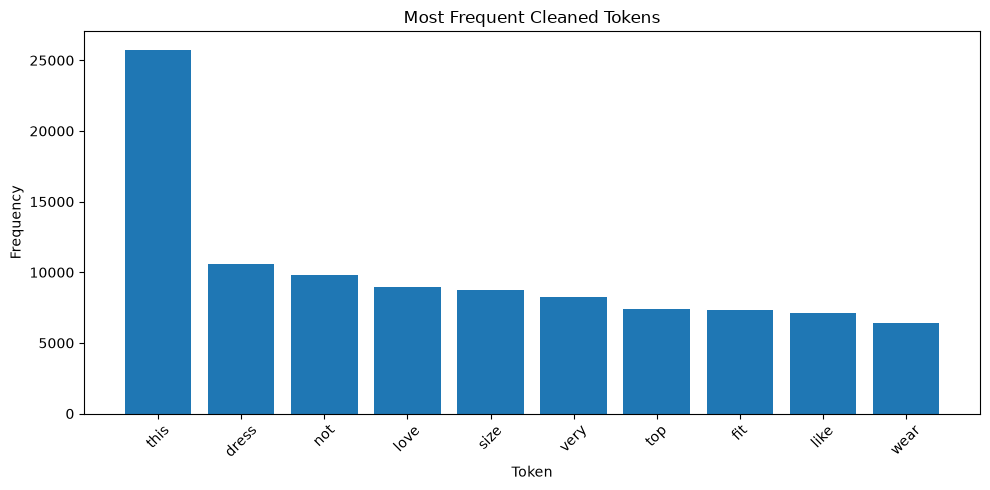

In [69]:
# Section 10 Python cell

top_df: pl.DataFrame = freq_df.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_df["token"], top_df["len"])

ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)

plt.title("Most Frequent Cleaned Tokens")
plt.xlabel("Token")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Section 11. Compare Raw vs Clean Token Counts


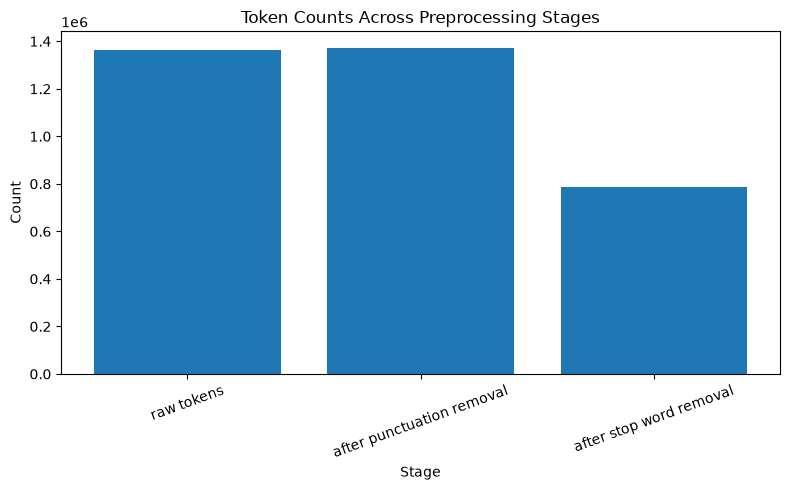

In [70]:
# Section 11 Python cell

plt.figure(figsize=(8, 5))
plt.bar(summary_df["stage"], summary_df["count"])

ax = plt.gca()
ax.tick_params(axis="x", labelrotation=20)

plt.title("Token Counts Across Preprocessing Stages")
plt.xlabel("Stage")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Reminder: "Run All" before sending to GitHub

Before saving a notebook (and running git add-commit-push),
**click 'Run All'** to generate all outputs and display them in the notebook. 

After git add-commit-push, **verify your notebook appears** in your GitHub repo. 

This is a Markdown cell.
